In [1]:
import matplotlib.pyplot as plt

In [2]:
import pandas as pd

In [3]:
TS = '..//data//20_engine01_timestamp_sample.csv'

In [4]:
# ── [개념] 문자열 날짜 → datetime 변환 ─────────────────────────────────────
# 형식: pd.to_datetime(열) → 글자를 진짜 시간 값으로. 변환 전후 dtype 확인.
df = pd.read_csv(TS)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 182 entries, 0 to 181
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  182 non-null    str    
 1   temp_out   182 non-null    float64
 2   temp_core  182 non-null    float64
 3   pressure   180 non-null    float64
 4   vibration  179 non-null    float64
 5   flow       182 non-null    float64
dtypes: float64(5), str(1)
memory usage: 12.0 KB


In [6]:
df['timestamp']

0      2024-03-01 00:00:00
1      2024-03-01 01:00:00
2      2024-03-01 02:00:00
3      2024-03-01 03:00:00
4      2024-03-01 04:00:00
              ...         
177    2024-03-08 19:00:00
178    2024-03-08 20:00:00
179    2024-03-08 21:00:00
180    2024-03-08 22:00:00
181    2024-03-08 23:00:00
Name: timestamp, Length: 182, dtype: str

In [7]:
df['timestamp'] == '2024-03-07'

0      False
1      False
2      False
3      False
4      False
       ...  
177    False
178    False
179    False
180    False
181    False
Name: timestamp, Length: 182, dtype: bool

In [8]:
df[df['timestamp'] == '2024-03-07']

,timestamp,temp_out,temp_core,pressure,vibration,flow


In [9]:
df['timestamp'].dtype

<StringDtype(na_value=nan)>

In [10]:
df['timestamp'].isna().sum()

np.int64(0)

In [12]:
pd.to_datetime(df['timestamp'])

0     2024-03-01 00:00:00
1     2024-03-01 01:00:00
2     2024-03-01 02:00:00
3     2024-03-01 03:00:00
4     2024-03-01 04:00:00
              ...        
177   2024-03-08 19:00:00
178   2024-03-08 20:00:00
179   2024-03-08 21:00:00
180   2024-03-08 22:00:00
181   2024-03-08 23:00:00
Name: timestamp, Length: 182, dtype: datetime64[us]

In [13]:
df['timestamp']=pd.to_datetime(df['timestamp'])

In [14]:
df['timestamp']

0     2024-03-01 00:00:00
1     2024-03-01 01:00:00
2     2024-03-01 02:00:00
3     2024-03-01 03:00:00
4     2024-03-01 04:00:00
              ...        
177   2024-03-08 19:00:00
178   2024-03-08 20:00:00
179   2024-03-08 21:00:00
180   2024-03-08 22:00:00
181   2024-03-08 23:00:00
Name: timestamp, Length: 182, dtype: datetime64[us]

In [15]:
df['timestamp'].dtype

dtype('<M8[us]')

In [18]:
df['timestamp'].dt.year

0      2024
1      2024
2      2024
3      2024
4      2024
       ... 
177    2024
178    2024
179    2024
180    2024
181    2024
Name: timestamp, Length: 182, dtype: int32

In [19]:
df['timestamp'].dt.month

0      3
1      3
2      3
3      3
4      3
      ..
177    3
178    3
179    3
180    3
181    3
Name: timestamp, Length: 182, dtype: int32

In [17]:
df['timestamp'].dt.day

0      1
1      1
2      1
3      1
4      1
      ..
177    8
178    8
179    8
180    8
181    8
Name: timestamp, Length: 182, dtype: int32

In [20]:
df['timestamp'].dt.hour

0       0
1       1
2       2
3       3
4       4
       ..
177    19
178    20
179    21
180    22
181    23
Name: timestamp, Length: 182, dtype: int32

In [21]:
df['timestamp'].dt.minute

0      0
1      0
2      0
3      0
4      0
      ..
177    0
178    0
179    0
180    0
181    0
Name: timestamp, Length: 182, dtype: int32

In [23]:
df['timestamp'].dt.second

0      0
1      0
2      0
3      0
4      0
      ..
177    0
178    0
179    0
180    0
181    0
Name: timestamp, Length: 182, dtype: int32

In [24]:
dates = ['2023-01-01', '2023-02-30', 'invalid_date', '2023-03-15', None]


In [26]:
# pd.to_datetime(dates)

In [28]:
pd.to_datetime(dates, errors='coerce')

DatetimeIndex(['2023-01-01', 'NaT', 'NaT', '2023-03-15', 'NaT'], dtype='datetime64[us]', freq=None)

In [33]:
pd.to_datetime(dates, errors='coerce').isna().sum()

np.int64(3)

In [38]:
pd.to_datetime(dates, errors='coerce').isna().sum()

np.int64(3)

In [39]:
date_series = pd.to_datetime(dates, errors='coerce')

In [ ]:
#format='%Y-%m-%d'는 “반드시 YYYY-MM-DD 형태여야만 변환하고, 아니면 NaT로 처리하라”는 의미입니다.

In [40]:
date_series

DatetimeIndex(['2023-01-01', 'NaT', 'NaT', '2023-03-15', 'NaT'], dtype='datetime64[us]', freq=None)

In [41]:
date_series.dropna()

DatetimeIndex(['2023-01-01', '2023-03-15'], dtype='datetime64[us]', freq=None)

In [ ]:
# NaT가 있으면 인덱스 설정 시 문제 생길 수 있으므로 미리 처리

In [44]:
#pd.to_datetime(df['timestamp'], format='%Y-%m-%d', errors='coerce')

In [45]:
df_sample=pd.DataFrame({
    'timestamp': [
        '2024-01-15',   # 정상
        '2024-12-31',   # 정상
        '2024/01/15',   # 슬래시 (형식 불일치)
        '15-01-2024',   # 순서 다름
        '2024-1-5',     # 월/일 자릿수 다름
        'invalid',      # 아예 날짜 아님
        None            # 결측
    ]
})

In [46]:
# format을 지정한 경우
result = pd.to_datetime(
    df_sample['timestamp'],
    format='%Y-%m-%d',
    errors='coerce'
)

In [47]:
result

0   2024-01-15
1   2024-12-31
2          NaT
3          NaT
4   2024-01-05
5          NaT
6          NaT
Name: timestamp, dtype: datetime64[us]

In [48]:
# 02 시간 인덱스 다루기

In [49]:
TS = '..//data//20_engine01_timestamp_sample.csv'

In [50]:
df = pd.read_csv(TS)

In [51]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 182 entries, 0 to 181
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  182 non-null    str    
 1   temp_out   182 non-null    float64
 2   temp_core  182 non-null    float64
 3   pressure   180 non-null    float64
 4   vibration  179 non-null    float64
 5   flow       182 non-null    float64
dtypes: float64(5), str(1)
memory usage: 12.0 KB


In [52]:
df.columns

Index(['timestamp', 'temp_out', 'temp_core', 'pressure', 'vibration', 'flow'], dtype='str')

In [53]:
df['timestamp'].dtype

<StringDtype(na_value=nan)>

In [54]:
df['timestamp']=pd.to_datetime(df['timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

In [55]:
df['timestamp'].dtype

dtype('<M8[us]')

In [56]:
df.index

RangeIndex(start=0, stop=182, step=1)

In [57]:
df.head()

,timestamp,temp_out,temp_core,pressure,vibration,flow
0,2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
1,2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2,2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
3,2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
4,2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417


In [58]:
df.set_index('timestamp')

,temp_out,temp_core,pressure,vibration,flow
timestamp,,,,,
2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417
...,...,...,...,...,...
2024-03-08 19:00:00,642.60,1416.30,546.97,48.30,8.713
2024-03-08 20:00:00,642.38,1418.46,546.26,48.10,8.660
2024-03-08 21:00:00,642.93,1415.71,546.52,48.37,8.622


In [60]:
df.index

RangeIndex(start=0, stop=182, step=1)

In [61]:
df=df.set_index('timestamp')

In [62]:
df.index

DatetimeIndex(['2024-03-01 00:00:00', '2024-03-01 01:00:00',
               '2024-03-01 02:00:00', '2024-03-01 03:00:00',
               '2024-03-01 04:00:00', '2024-03-01 05:00:00',
               '2024-03-01 06:00:00', '2024-03-01 07:00:00',
               '2024-03-01 08:00:00', '2024-03-01 09:00:00',
               ...
               '2024-03-08 14:00:00', '2024-03-08 15:00:00',
               '2024-03-08 16:00:00', '2024-03-08 17:00:00',
               '2024-03-08 18:00:00', '2024-03-08 19:00:00',
               '2024-03-08 20:00:00', '2024-03-08 21:00:00',
               '2024-03-08 22:00:00', '2024-03-08 23:00:00'],
              dtype='datetime64[us]', name='timestamp', length=182, freq=None)

In [65]:
df.index

DatetimeIndex(['2024-03-01 00:00:00', '2024-03-01 01:00:00',
               '2024-03-01 02:00:00', '2024-03-01 03:00:00',
               '2024-03-01 04:00:00', '2024-03-01 05:00:00',
               '2024-03-01 06:00:00', '2024-03-01 07:00:00',
               '2024-03-01 08:00:00', '2024-03-01 09:00:00',
               ...
               '2024-03-08 14:00:00', '2024-03-08 15:00:00',
               '2024-03-08 16:00:00', '2024-03-08 17:00:00',
               '2024-03-08 18:00:00', '2024-03-08 19:00:00',
               '2024-03-08 20:00:00', '2024-03-08 21:00:00',
               '2024-03-08 22:00:00', '2024-03-08 23:00:00'],
              dtype='datetime64[us]', name='timestamp', length=182, freq=None)

In [68]:
type(df.index)

pandas.DatetimeIndex

In [70]:
type(df.index).__name__

'DatetimeIndex'

In [71]:
df.head()

,temp_out,temp_core,pressure,vibration,flow
timestamp,,,,,
2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417


In [72]:
df.loc['2024-03-01 01:00:00']

temp_out      640.660
temp_core    1399.280
pressure      553.060
vibration      47.060
flow            8.385
Name: 2024-03-01 01:00:00, dtype: float64

In [73]:
#정리

In [74]:
TS = '..//data//20_engine01_timestamp_sample.csv'
df = pd.read_csv(TS)
df['timestamp']=pd.to_datetime(df['timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

In [75]:

# ── [개념] set_index · sort_index (시간 분석 준비 3박자) ────────────────────
df = df.set_index('timestamp').sort_index()

In [77]:
df.head()

,temp_out,temp_core,pressure,vibration,flow
timestamp,,,,,
2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417


In [78]:
df.loc['2024-03-01']

,temp_out,temp_core,pressure,vibration,flow
timestamp,,,,,
2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417
2024-03-01 05:00:00,641.13,1402.62,554.33,47.18,8.408
2024-03-01 06:00:00,641.01,1408.20,553.86,47.23,8.418
2024-03-01 07:00:00,640.84,1395.14,554.98,47.25,8.379
2024-03-01 08:00:00,641.27,1401.75,552.66,47.35,8.421


In [79]:
df.loc['2024-03']

,temp_out,temp_core,pressure,vibration,flow
timestamp,,,,,
2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417
...,...,...,...,...,...
2024-03-08 19:00:00,642.60,1416.30,546.97,48.30,8.713
2024-03-08 20:00:00,642.38,1418.46,546.26,48.10,8.660
2024-03-08 21:00:00,642.93,1415.71,546.52,48.37,8.622


In [80]:
df.loc['2024-03-01 09:00:00']

temp_out      640.900
temp_core    1402.830
pressure      553.980
vibration      47.400
flow            8.438
Name: 2024-03-01 09:00:00, dtype: float64

In [81]:
df.loc['2024-03-01' : '2024-03-03' ]

,temp_out,temp_core,pressure,vibration,flow
timestamp,,,,,
2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417
...,...,...,...,...,...
2024-03-03 19:00:00,641.88,1406.88,551.18,47.76,8.469
2024-03-03 20:00:00,641.78,1396.47,550.29,47.88,8.515
2024-03-03 21:00:00,641.48,1406.17,550.42,47.68,8.462


In [82]:
print(len(df.loc['2024-03-01']))
print(len(df.loc['2024-03-02']))
print(len(df.loc['2024-03-03']))

22
20
24


In [83]:
# 03 시간 단위 집계

In [84]:
df.columns

Index(['temp_out', 'temp_core', 'pressure', 'vibration', 'flow'], dtype='str')

In [86]:
df['temp_core'].resample('D')

In [87]:
list(df['temp_core'].resample('D'))

[(Timestamp('2024-03-01 00:00:00'),
  timestamp
  2024-03-01 00:00:00    1399.16
  2024-03-01 01:00:00    1399.28
  2024-03-01 02:00:00    1394.97
  2024-03-01 03:00:00    1404.10
  2024-03-01 04:00:00    1400.33
  2024-03-01 05:00:00    1402.62
  2024-03-01 06:00:00    1408.20
  2024-03-01 07:00:00    1395.14
  2024-03-01 08:00:00    1401.75
  2024-03-01 09:00:00    1402.83
  2024-03-01 12:00:00    1403.28
  2024-03-01 13:00:00    1405.67
  2024-03-01 14:00:00    1403.43
  2024-03-01 15:00:00    1404.60
  2024-03-01 16:00:00    1402.39
  2024-03-01 17:00:00    1405.09
  2024-03-01 18:00:00    1400.91
  2024-03-01 19:00:00    1405.04
  2024-03-01 20:00:00    1400.08
  2024-03-01 21:00:00    1408.19
  2024-03-01 22:00:00    1410.92
  2024-03-01 23:00:00    1400.37
  Name: temp_core, dtype: float64),
 (Timestamp('2024-03-02 00:00:00'),
  timestamp
  2024-03-02 00:00:00    1396.21
  2024-03-02 02:00:00    1404.00
  2024-03-02 03:00:00    1403.48
  2024-03-02 04:00:00    1402.21
  2024-03-

In [88]:
len(list(df['temp_core'].resample('D')))

8

In [89]:
list(df['temp_core'].resample('D'))[0]

(Timestamp('2024-03-01 00:00:00'),
 timestamp
 2024-03-01 00:00:00    1399.16
 2024-03-01 01:00:00    1399.28
 2024-03-01 02:00:00    1394.97
 2024-03-01 03:00:00    1404.10
 2024-03-01 04:00:00    1400.33
 2024-03-01 05:00:00    1402.62
 2024-03-01 06:00:00    1408.20
 2024-03-01 07:00:00    1395.14
 2024-03-01 08:00:00    1401.75
 2024-03-01 09:00:00    1402.83
 2024-03-01 12:00:00    1403.28
 2024-03-01 13:00:00    1405.67
 2024-03-01 14:00:00    1403.43
 2024-03-01 15:00:00    1404.60
 2024-03-01 16:00:00    1402.39
 2024-03-01 17:00:00    1405.09
 2024-03-01 18:00:00    1400.91
 2024-03-01 19:00:00    1405.04
 2024-03-01 20:00:00    1400.08
 2024-03-01 21:00:00    1408.19
 2024-03-01 22:00:00    1410.92
 2024-03-01 23:00:00    1400.37
 Name: temp_core, dtype: float64)

In [90]:
list(df['temp_core'].resample('D'))[0][1]

timestamp
2024-03-01 00:00:00    1399.16
2024-03-01 01:00:00    1399.28
2024-03-01 02:00:00    1394.97
2024-03-01 03:00:00    1404.10
2024-03-01 04:00:00    1400.33
2024-03-01 05:00:00    1402.62
2024-03-01 06:00:00    1408.20
2024-03-01 07:00:00    1395.14
2024-03-01 08:00:00    1401.75
2024-03-01 09:00:00    1402.83
2024-03-01 12:00:00    1403.28
2024-03-01 13:00:00    1405.67
2024-03-01 14:00:00    1403.43
2024-03-01 15:00:00    1404.60
2024-03-01 16:00:00    1402.39
2024-03-01 17:00:00    1405.09
2024-03-01 18:00:00    1400.91
2024-03-01 19:00:00    1405.04
2024-03-01 20:00:00    1400.08
2024-03-01 21:00:00    1408.19
2024-03-01 22:00:00    1410.92
2024-03-01 23:00:00    1400.37
Name: temp_core, dtype: float64

In [91]:
list(df['temp_core'].resample('D'))[0][1].mean()

np.float64(1402.652272727273)

In [96]:
pd.set_option('display.precision',2)

In [97]:
df['temp_core'].resample('D').mean()

timestamp
2024-03-01    1402.65
2024-03-02    1403.83
2024-03-03    1405.56
2024-03-04    1409.59
2024-03-05    1410.55
2024-03-06    1412.70
2024-03-07    1413.76
2024-03-08    1415.23
Freq: D, Name: temp_core, dtype: float64

In [93]:
df['temp_core'].resample('D').max()

timestamp
2024-03-01    1410.92
2024-03-02    1411.56
2024-03-03    1413.84
2024-03-04    1414.84
2024-03-05    1416.21
2024-03-06    1417.43
2024-03-07    1422.94
2024-03-08    1422.53
Freq: D, Name: temp_core, dtype: float64

In [98]:
df['temp_core'].resample('D').agg(['mean','max'])

,mean,max
timestamp,,
2024-03-01,1402.65,1410.92
2024-03-02,1403.83,1411.56
2024-03-03,1405.56,1413.84
2024-03-04,1409.59,1414.84
2024-03-05,1410.55,1416.21
2024-03-06,1412.70,1417.43
2024-03-07,1413.76,1422.94
2024-03-08,1415.23,1422.53


In [99]:
df['temp_core'].resample('D').agg(['mean','max']).T

timestamp,2024-03-01,2024-03-02,2024-03-03,2024-03-04,2024-03-05,2024-03-06,2024-03-07,2024-03-08
mean,1402.65,1403.83,1405.56,1409.59,1410.55,1412.70,1413.76,1415.23
max,1410.92,1411.56,1413.84,1414.84,1416.21,1417.43,1422.94,1422.53


In [100]:
list(range(3,10))

[3, 4, 5, 6, 7, 8, 9]

In [101]:
import numpy as np

In [102]:
np.arange(4,10)

array([4, 5, 6, 7, 8, 9])

In [105]:
pd.date_range('2026-11-02',periods=7, freq='D' )

DatetimeIndex(['2026-11-02', '2026-11-03', '2026-11-04', '2026-11-05',
               '2026-11-06', '2026-11-07', '2026-11-08'],
              dtype='datetime64[us]', freq='D')

In [107]:
pd.date_range('2026-11-02',periods=7, freq='B' )

DatetimeIndex(['2026-11-02', '2026-11-03', '2026-11-04', '2026-11-05',
               '2026-11-06', '2026-11-09', '2026-11-10'],
              dtype='datetime64[us]', freq='B')

In [108]:
# 간단한 시계열 데이터 (하루 단위)
dates = pd.date_range('2024-01-01', periods=6, freq='D')
s = pd.Series([10, 20, 30, 40, 50, 60], index=dates)


In [109]:
s

2024-01-01    10
2024-01-02    20
2024-01-03    30
2024-01-04    40
2024-01-05    50
2024-01-06    60
Freq: D, dtype: int64

In [110]:
# 1. asfreq – 단순 빈도 변환 (값 계산 없음)

# 2일 단위로 바꾸기
print(s.asfreq('2D'))


2024-01-01    10
2024-01-03    30
2024-01-05    50
Freq: 2D, dtype: int64


In [111]:
#2. resample – 그룹으로 묶어서 계산
# 2일 단위로 묶어서 평균 구하기
print(s.resample('2D').mean())


2024-01-01    15.0
2024-01-03    35.0
2024-01-05    55.0
Freq: 2D, dtype: float64


In [112]:
#3시 5분에 시작

In [113]:
len(df['temp_core'])

182

In [118]:
df['temp_core'].isna().sum()

np.int64(0)

In [115]:
list(df['temp_core'].resample('30min'))

[(Timestamp('2024-03-01 00:00:00'),
  timestamp
  2024-03-01    1399.16
  Name: temp_core, dtype: float64),
 (Timestamp('2024-03-01 00:30:00'),
  Series([], Name: temp_core, dtype: float64)),
 (Timestamp('2024-03-01 01:00:00'),
  timestamp
  2024-03-01 01:00:00    1399.28
  Name: temp_core, dtype: float64),
 (Timestamp('2024-03-01 01:30:00'),
  Series([], Name: temp_core, dtype: float64)),
 (Timestamp('2024-03-01 02:00:00'),
  timestamp
  2024-03-01 02:00:00    1394.97
  Name: temp_core, dtype: float64),
 (Timestamp('2024-03-01 02:30:00'),
  Series([], Name: temp_core, dtype: float64)),
 (Timestamp('2024-03-01 03:00:00'),
  timestamp
  2024-03-01 03:00:00    1404.1
  Name: temp_core, dtype: float64),
 (Timestamp('2024-03-01 03:30:00'),
  Series([], Name: temp_core, dtype: float64)),
 (Timestamp('2024-03-01 04:00:00'),
  timestamp
  2024-03-01 04:00:00    1400.33
  Name: temp_core, dtype: float64),
 (Timestamp('2024-03-01 04:30:00'),
  Series([], Name: temp_core, dtype: float64)),
 (Tim

In [117]:
list(df['temp_core'].resample('30min'))[1:3]

[(Timestamp('2024-03-01 00:30:00'),
  Series([], Name: temp_core, dtype: float64)),
 (Timestamp('2024-03-01 01:00:00'),
  timestamp
  2024-03-01 01:00:00    1399.28
  Name: temp_core, dtype: float64)]

In [119]:
up=df['temp_core'].resample('30min').mean()

In [121]:
type(up)

pandas.Series

In [122]:
up

timestamp
2024-03-01 00:00:00    1399.16
2024-03-01 00:30:00        NaN
2024-03-01 01:00:00    1399.28
2024-03-01 01:30:00        NaN
2024-03-01 02:00:00    1394.97
                        ...   
2024-03-08 21:00:00    1415.71
2024-03-08 21:30:00        NaN
2024-03-08 22:00:00    1412.78
2024-03-08 22:30:00        NaN
2024-03-08 23:00:00    1419.19
Freq: 30min, Name: temp_core, Length: 383, dtype: float64

In [123]:
up.isna().sum()

np.int64(201)

In [126]:
#help(up.interpolate)

In [127]:
up_filled=up.interpolate()

In [128]:
up_filled.isna().sum()

np.int64(0)

In [129]:
up_filled.head()

timestamp
2024-03-01 00:00:00    1399.16
2024-03-01 00:30:00    1399.22
2024-03-01 01:00:00    1399.28
2024-03-01 01:30:00    1397.12
2024-03-01 02:00:00    1394.97
Freq: 30min, Name: temp_core, dtype: float64

In [130]:
#실습1 3시 25분

In [131]:
TS = '..//data//20_engine01_timestamp_sample.csv'
df = pd.read_csv(TS)
df['timestamp']=pd.to_datetime(df['timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

In [134]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 182 entries, 0 to 181
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   timestamp  182 non-null    datetime64[us]
 1   temp_out   182 non-null    float64       
 2   temp_core  182 non-null    float64       
 3   pressure   180 non-null    float64       
 4   vibration  179 non-null    float64       
 5   flow       182 non-null    float64       
dtypes: datetime64[us](1), float64(5)
memory usage: 8.7 KB


In [132]:
df['timestamp'].dtype

dtype('<M8[us]')

In [137]:
# [ns]나노초 (기본값)[us]마이크로초[ms]밀리초

In [136]:
# NumPy에서 datetime64의 타입 문자 코드로 M(대문자)을 쓰도록 정한 것이고, timedelta64는 m(소문자)을 씁니다.

In [135]:
#실습2 3시 30분

In [139]:
df['timestamp'].dt.year[0]

np.int32(2024)

In [140]:
# ── [실습 2] 시간 조각 추출과 파생 열 ───────────────────────────────────────
print(df['timestamp'].dt.year.iloc[0], df['timestamp'].dt.month.iloc[0])   # 2024 3
print(df['timestamp'].dt.day.iloc[0], df['timestamp'].dt.hour.iloc[0])     # 1 0
df['hour'] = df['timestamp'].dt.hour
print(df['hour'].head(3).tolist())                    # [0, 1, 2]

2024 3
1 0
[0, 1, 2]


In [141]:
# 실습3 3시 35분

In [142]:
# ── [실습 3] 시간 인덱스 만들고 정렬 ────────────────────────────────────────
df = df.set_index('timestamp').sort_index()
print(type(df.index).__name__)                        # DatetimeIndex
print(df.index[0], '~', df.index[-1])                 # 2024-03-01 00:00:00 ~ 2024-03-08 23:00:00
print('전체 행:', len(df))                             # 182

DatetimeIndex
2024-03-01 00:00:00 ~ 2024-03-08 23:00:00
전체 행: 182


In [143]:
# 실습 4 3시 40분

In [144]:
# ── [실습 4] 시간 인덱스로 기간 잘라보기 ────────────────────────────────────
day = df.loc['2024-03-02']
print('3월 2일 행:', len(day))                         # 20
span = df.loc['2024-03-05':'2024-03-07']
print('사흘 행:', len(span))                           # 70 (끝 날짜 포함)

3월 2일 행: 20
사흘 행: 70


In [146]:
# 실습 5 3시 45분 temp_out

In [147]:
df['temp_out'].resample('6h').mean().head()

timestamp
2024-03-01 00:00:00    641.06
2024-03-01 06:00:00    641.00
2024-03-01 12:00:00    640.95
2024-03-01 18:00:00    641.23
2024-03-02 00:00:00    641.37
Freq: 6h, Name: temp_out, dtype: float64

In [149]:
df['temp_out'].resample('6h').max().head()

timestamp
2024-03-01 00:00:00    641.18
2024-03-01 06:00:00    641.27
2024-03-01 12:00:00    641.23
2024-03-01 18:00:00    641.65
2024-03-02 00:00:00    642.00
Freq: 6h, Name: temp_out, dtype: float64

In [ ]:
# 실습 6, 7 3시 55분 temp_out 

In [153]:
# 4시 10분에 다시 시작하겠습니다. 제출

In [155]:
df['temp_out'].resample('h').mean()

timestamp
2024-03-01 00:00:00    641.17
2024-03-01 01:00:00    640.66
2024-03-01 02:00:00    641.08
2024-03-01 03:00:00    641.18
2024-03-01 04:00:00    641.13
                        ...  
2024-03-08 19:00:00    642.60
2024-03-08 20:00:00    642.38
2024-03-08 21:00:00    642.93
2024-03-08 22:00:00    642.22
2024-03-08 23:00:00    642.04
Freq: h, Name: temp_out, Length: 192, dtype: float64

In [158]:
# ── [실습 6] 리샘플링 단위와 데이터 성김 (다운샘플링) ───────────────────────
for f in ['h', '6h', '12h']:
    n = len(df['temp_out'].resample(f).mean())
    #print(n)
    print(f, '단위 행:', n)                            # h 192, 6h 32, 12h 16

h 단위 행: 192
6h 단위 행: 32
12h 단위 행: 16


In [159]:
# ── [실습 7] 일별 집계로 추세 확인 ──────────────────────────────────────────
daily = df['temp_out'].resample('D').mean()

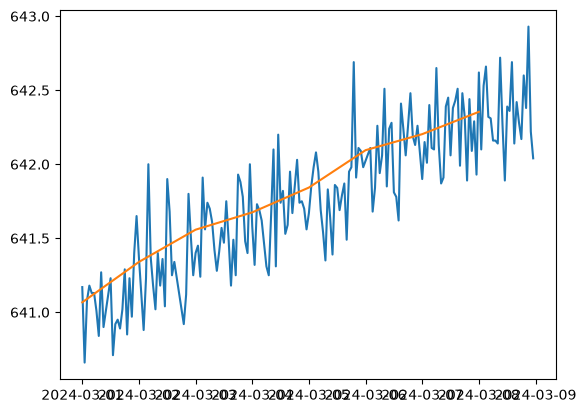

In [160]:
plt.plot(df.index, df['temp_out'])
plt.plot(daily.index, daily.values)
plt.show()

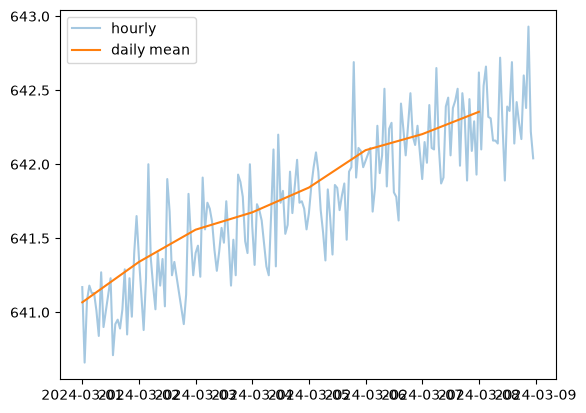

In [161]:
plt.plot(df.index, df['temp_out'], alpha=0.4, label='hourly')
plt.plot(daily.index, daily.values, label='daily mean')
plt.legend()
plt.show()

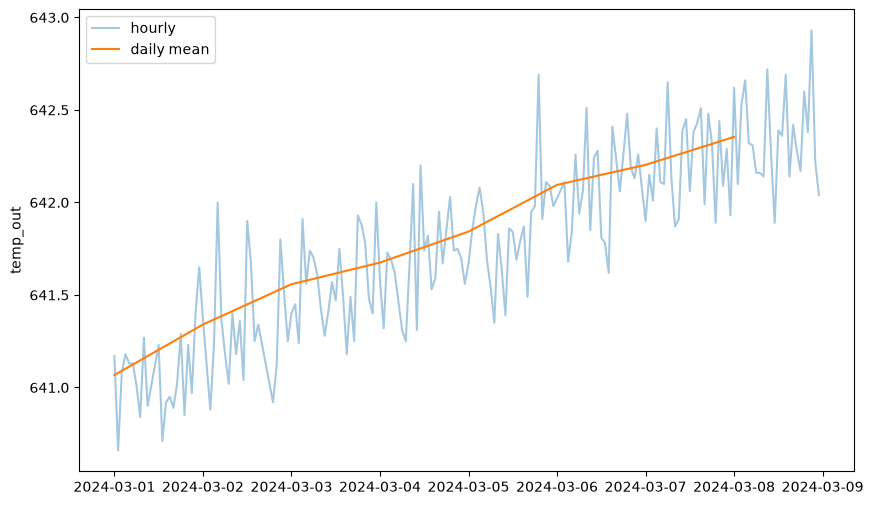

In [164]:
plt.figure(figsize=(10,6))
plt.plot(df.index, df['temp_out'], alpha=0.4, label='hourly')
plt.plot(daily.index, daily.values, label='daily mean')
plt.ylabel('temp_out')
plt.legend()
plt.show()

In [167]:
# 실습8 4시 20분 flow, vibration

In [168]:
# ── [실습 8] 업샘플링 결측과 보간 ───────────────────────────────────────────
up = df['flow'].resample('30min').mean()

In [169]:
up

timestamp
2024-03-01 00:00:00    8.34
2024-03-01 00:30:00     NaN
2024-03-01 01:00:00    8.38
2024-03-01 01:30:00     NaN
2024-03-01 02:00:00    8.44
                       ... 
2024-03-08 21:00:00    8.62
2024-03-08 21:30:00     NaN
2024-03-08 22:00:00    8.68
2024-03-08 22:30:00     NaN
2024-03-08 23:00:00    8.64
Freq: 30min, Name: flow, Length: 383, dtype: float64

In [170]:
print('업샘플링 결측:', int(up.isna().sum()))            # 201

업샘플링 결측: 201


In [171]:
print('보간 후:', int(up.interpolate().isna().sum()))    # 0

보간 후: 0


In [172]:
print('진동 원본 결측:', int(df['vibration'].isna().sum()))          # 3
print('진동 보간 후:', int(df['vibration'].interpolate().isna().sum()))  # 0
print('=== 20_02 전체 실행 완료 ===')

진동 원본 결측: 3
진동 보간 후: 0
=== 20_02 전체 실행 완료 ===
